In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import pandas as pd
import numpy as np

Apply multiple preprocessing steps one after another.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [3]:
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 477kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.37MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.17MB/s]


In [4]:
print(dataset[0])

(tensor([[[-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
          -1.0000, -1.0000, -1.0000, -1.0000, -

1  = channel
28 = height
28 = width

In [5]:
image, label = dataset[0]
print(f'image shape: {image.shape}, label:{label}')

image shape: torch.Size([1, 28, 28]), label:5


Using small part of dataset

In [7]:
small_dataset, _ = random_split(dataset, [20000, 40000])
print(len(small_dataset))

20000


In [6]:
train_data, val_data, test_data = random_split(dataset, [40000,10000, 10000])

In [8]:
train_loader = DataLoader(train_data, batch_size = 64, shuffle= True)
test_loader = DataLoader(test_data, batch_size = 64, shuffle= False)
val_loader = DataLoader(val_data, batch_size = 64, shuffle= False)

In [9]:
print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))


images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Train: 40000
Validation: 10000
Test: 10000
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


Create random noise,
Why random noise?
We want to deliberately corrupt our clean image.

In [10]:
noise = torch.randn_like(images)
print(noise.shape)

torch.Size([64, 1, 28, 28])


simple noise experiment

In [ ]:
noise_level = 0.3

noisy_images = images + noise_level * noise

0.1 → slightly noisy
0.5 → much noisier
1.0 → heavily corrupted

In [ ]:
import matplotlib.pyplot as plt

original = images[0]
noise_img = noise[0]

noisy_1 = original + 0.1 * noise_img
noisy_2 = original + 0.5 * noise_img
noisy_3 = original + 1.0 * noise_img

In [ ]:
# images, labels = next(iter(train_loader))

# noise = torch.randn_like(images)

# print("Images:", images.shape)
# print("Noise:", noise.shape)

# print("Noise mean:", noise.mean())
# print("Noise std:", noise.std())

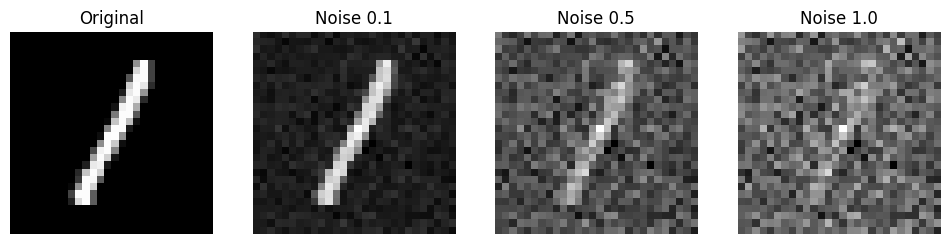

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(original.squeeze(), cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(noisy_1.squeeze(), cmap="gray")
axes[1].set_title("Noise 0.1")

axes[2].imshow(noisy_2.squeeze(), cmap="gray")
axes[2].set_title("Noise 0.5")

axes[3].imshow(noisy_3.squeeze(), cmap="gray")
axes[3].set_title("Noise 1.0")

for ax in axes:
    ax.axis("off")

plt.show()

Create the noise schedule




*   T = 100 means 100 diffusion steps,
*   beta = how much noise we add at each diffusion step,
*   alpha = how much original image information we keep,

t = 0 almost clean, t = 50 slightly noisy, t = 250 quite noisy, t = 450 very noisy, t = 499 almost random noise

beta[0]   ≈ 0.0001 ... beta[499] ≈ 0.02




In [12]:
T = 500

beta = torch.linspace(0.0001, 0.02, T) #noise

alpha = 1.0 - beta # original image info

alpha_bar = torch.cumprod(alpha, dim=0) #which dictates how much of the original image's signal remains

* x0: original clean image
* xt : image at timestep t
* noise = target

In [ ]:
def add_noise(x0, t):
    noise = torch.randn_like(x0)

    alpha_bar_t = alpha_bar[t]

    # the noisy version of the original data x0 at timestep t [diffusion model]
    xt = ( torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1 - alpha_bar_t) * noise )

    return xt, noise

In [ ]:
# import torch.nn as nn

# class SimpleDiffusionModel(nn.Module):
#     def __init__(self):
#         super().__init__()

#         self.class_embedding = nn.Embedding(10, 28 * 28)

#         self.model = nn.Sequential(
#             nn.Conv2d(3, 32, 3, padding=1),
#             nn.ReLU(),

#             nn.Conv2d(32, 64, 3, padding=1),
#             nn.ReLU(),

#             nn.Conv2d(64, 64, 3, padding=1),
#             nn.ReLU(),

#             nn.Conv2d(64, 32, 3, padding=1),
#             nn.ReLU(),

#             nn.Conv2d(32, 1, 3, padding=1)
#         )

#     def forward(self, x, t, labels):
#         batch_size = x.shape[0]

#         t = t.float() / T

#         t_channel = t.view( batch_size, 1, 1, 1 ).expand( batch_size, 1, 28, 28 )

#         class_embedding = self.class_embedding(labels)

#         class_channel = class_embedding.view( batch_size, 1, 28, 28 )

#         x = torch.cat( [x, t_channel, class_channel], dim=1 )

#         return self.model(x)

In [ ]:
import torch
import torch.nn as nn

class SimpleDiffusionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.class_embedding = nn.Embedding(10, 28 * 28)

        # Downsampling
        self.down1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), #3 : Channel 1 = noisy image, Channel 2 = timestep, Channel 3 = class information
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU()
        )

        self.pool1 = nn.MaxPool2d(2) #It halves height and width.

        self.down2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2)

        # Bottom
        self.bottom = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU()
        )

        # Upsampling
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2 )

        self.up_conv1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d( 64, 32, kernel_size=2, stride=2 )

        self.up_conv2 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU()
        )

        self.output = nn.Conv2d(
            32, 1,
            kernel_size=1
        )

    def forward(self, x, t, labels): #x = noisy image, t = timestep, labels = requested digit

        batch_size = x.shape[0]

        # Normalize timestep
        t = t.float() / T

        # Turn timestep into image-like channel
        t_channel = t.view( batch_size, 1, 1, 1 ).expand( batch_size, 1, 28, 28 )

        class_embedding = self.class_embedding(labels)

        class_channel = class_embedding.view( batch_size, 1, 28, 28 )

        # noisy image + timestep
        x = torch.cat( [x, t_channel, class_channel], dim=1 )

        # Down path
        d1 = self.down1(x)          # [B, 32, 28, 28]

        p1 = self.pool1(d1)         # [B, 32, 14, 14]

        d2 = self.down2(p1)         # [B, 64, 14, 14]

        p2 = self.pool2(d2)         # [B, 64, 7, 7]

        # Bottom
        b = self.bottom(p2)         # [B, 128, 7, 7]

        # Up path
        u1 = self.up1(b)            # [B, 64, 14, 14]

        u1 = torch.cat( [u1, d2], dim=1 ) # [B, 128, 14, 14]

        u1 = self.up_conv1(u1)      # [B, 64, 14, 14]

        u2 = self.up2(u1)           # [B, 32, 28, 28]

        u2 = torch.cat([u2, d1], dim=1 )  # [B, 64, 28, 28]

        u2 = self.up_conv2(u2)      # [B, 32, 28, 28]

        return self.output(u2)

In [ ]:
model = SimpleDiffusionModel()

print(model)

SimpleDiffusionModel(
  (class_embedding): Embedding(10, 784)
  (down1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottom): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (up1): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
  (up_conv1): Sequential(
    (0): Conv2d(128, 64, kernel_size=(3, 

small test

In [ ]:
# images, labels = next(iter(train_loader))

# batch_size = images.shape[0]

# t = torch.randint(
#     0,
#     T,
#     (batch_size,)
# )

# noise = torch.randn_like(images)

# alpha_bar_t = alpha_bar[t].view(
#     batch_size, 1, 1, 1
# )

# noisy_images = (
#     torch.sqrt(alpha_bar_t) * images
#     +
#     torch.sqrt(1 - alpha_bar_t) * noise
# )

# predicted_noise = model(
#     noisy_images,
#     t
# )

# print("Noisy images:", noisy_images.shape)
# print("Actual noise:", noise.shape)
# print("Predicted noise:", predicted_noise.shape)

In [ ]:
import torch.nn.functional as F

# loss = F.mse_loss(predicted_noise, noise)
# print(loss)

optimizer = torch.optim.Adam( model.parameters(), lr=2e-4 )

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu" )

print(device)

model = model.to(device)

beta = beta.to(device)
alpha = alpha.to(device)
alpha_bar = alpha_bar.to(device)

cuda


In [ ]:
epochs = 30

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        batch_size = images.shape[0]

        # Random timestep for every image
        t = torch.randint( 0, T, (batch_size,), device=device )

        # Create random Gaussian noise
        noise = torch.randn_like(images)

        # Get alpha_bar for each selected timestep
        alpha_bar_t = alpha_bar[t].view(batch_size, 1, 1, 1 )

        # Forward diffusion
        noisy_images = (
            torch.sqrt(alpha_bar_t) * images
            +
            torch.sqrt(1 - alpha_bar_t) * noise
        )

        # Predict the noise
        predicted_noise = model(noisy_images, t, labels)

        # Compare predicted noise with real noise
        loss = F.mse_loss(predicted_noise,noise)

        # Remove old gradients
        optimizer.zero_grad()

        # Calculate new gradients
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"- Loss: {average_loss:.4f}"
    )

Epoch 1/30 - Loss: 0.2413
Epoch 2/30 - Loss: 0.0904
Epoch 3/30 - Loss: 0.0726
Epoch 4/30 - Loss: 0.0633
Epoch 5/30 - Loss: 0.0589
Epoch 6/30 - Loss: 0.0554
Epoch 7/30 - Loss: 0.0532
Epoch 8/30 - Loss: 0.0506
Epoch 9/30 - Loss: 0.0495
Epoch 10/30 - Loss: 0.0477
Epoch 11/30 - Loss: 0.0469
Epoch 12/30 - Loss: 0.0455
Epoch 13/30 - Loss: 0.0451
Epoch 14/30 - Loss: 0.0438
Epoch 15/30 - Loss: 0.0439
Epoch 16/30 - Loss: 0.0433
Epoch 17/30 - Loss: 0.0423
Epoch 18/30 - Loss: 0.0418
Epoch 19/30 - Loss: 0.0420
Epoch 20/30 - Loss: 0.0414
Epoch 21/30 - Loss: 0.0407
Epoch 22/30 - Loss: 0.0402
Epoch 23/30 - Loss: 0.0396
Epoch 24/30 - Loss: 0.0397
Epoch 25/30 - Loss: 0.0391
Epoch 26/30 - Loss: 0.0389
Epoch 27/30 - Loss: 0.0385
Epoch 28/30 - Loss: 0.0382
Epoch 29/30 - Loss: 0.0382
Epoch 30/30 - Loss: 0.0376


In [ ]:
model.eval()

val_loss = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        batch_size = images.shape[0]

        t = torch.randint( 0, T, (batch_size,), device=device )

        noise = torch.randn_like(images)

        alpha_bar_t = alpha_bar[t].view( batch_size, 1, 1, 1 )

        noisy_images = (
            torch.sqrt(alpha_bar_t) * images
            +
            torch.sqrt(1 - alpha_bar_t) * noise
        )

        predicted_noise = model( noisy_images, t, labels )

        loss = F.mse_loss( predicted_noise, noise )

        val_loss += loss.item()

val_loss = val_loss / len(val_loader)

print("Validation Loss:", val_loss)

Validation Loss: 0.036921386114636044


# Generate new image

In [ ]:
model.eval()

labels = torch.arange(10, device=device, dtype=torch.long)

x = torch.randn( 10, 1, 28, 28, device=device )

with torch.no_grad():

    for t in reversed(range(T)):

        # t_tensor = torch.tensor( [t], device=device, dtype=torch.long )
        t_tensor = torch.full( (10,), t, device=device, dtype=torch.long )

        predicted_noise = model( x, t_tensor, labels )

        alpha_t = alpha[t]
        alpha_bar_t = alpha_bar[t]
        beta_t = beta[t]

        x = ( 1 / torch.sqrt(alpha_t) ) * (x - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * predicted_noise )

        if t > 0:
            noise = torch.randn_like(x)
            x = x + torch.sqrt(beta_t) * noise

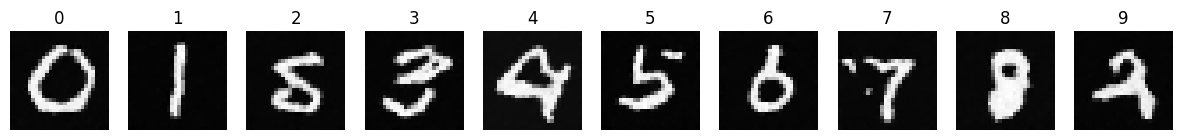

In [ ]:
fig, axes = plt.subplots(
    1, 10,
    figsize=(15, 2)
)

for i in range(10):

    axes[i].imshow(
        x[i].squeeze().cpu(),
        cmap="gray"
    )

    axes[i].set_title(str(i))
    axes[i].axis("off")

plt.show()